# Metric Stat Analysis – PSNR Score for PPP Radar Evaluation

This notebook mirrors the structure of the Pearson-analysis notebook, but replaces the calibration statistic by a **PSNR-based similarity score** between the predicted heatmap `pred_lambda` and the binary ground-truth support `gt_support`.

It loads pre-exported HDF5 evaluation files (`rank00.h5` – `rank03.h5`) produced by the metric evaluation pipeline and provides:

- first-look visualisation of `img`, `pred_lambda`, and `gt_support`
- interactive browsing through samples
- per-sample PSNR analysis on selected samples
- full-dataset PSNR comparison across model runs

Each h5 file is assumed to organise samples as:

```text
sample_XXXXXX/
    img          (H, W, 3)  uint8
    pred_lambda  (H, W)     float32
    gt_support   (H, W)     float32

In [1]:
import os
import glob

import h5py
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display, clear_output
import ipywidgets as widgets


import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (18, 5)
plt.rcParams["image.cmap"] = "hot"

## 2 · Configuration & Path Setup

In [2]:
# ---------------------------------------------------------------------------
# Paths – one entry per model run
# Replace these paths with your actual evaluation folders
# ---------------------------------------------------------------------------

H5_DIRS = {
    "test_gen_data_meric_1500_13606074": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test"
    ),
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608_LR_load_model40000": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
}

# Pick one model for the interactive sample inspection below
ACTIVE_MODEL = 'test_gen_data_meric_13600264'

# Numerical stability
EPS = 1e-12

## 3 · H5 Helper – List & Load Samples

In [3]:
def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) tuples across all rank files,
    sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from an h5 file.

    Returns a dict with:
      img          – (H, W, 3) uint8
      pred_lambda  – (H, W) float32
      gt_support   – (H, W) float32
      meta         – small metadata dict
    """
    with h5py.File(h5_path, "r") as f:
        g = f[sample_key]

        img = g["img"][()]
        pred_lambda = g["pred_lambda"][()]
        gt_support = g["gt_support"][()]

    return {
        "img": img,
        "pred_lambda": pred_lambda,
        "gt_support": gt_support,
        "meta": {
            "h5_file": os.path.basename(h5_path),
            "sample_key": sample_key,
        }
    }


active_h5_files = sorted(glob.glob(os.path.join(H5_DIRS[ACTIVE_MODEL], "rank*.h5")))
assert active_h5_files, f"No rank*.h5 files found in: {H5_DIRS[ACTIVE_MODEL]}"

all_samples = list_h5_samples(active_h5_files)
assert all_samples, "No samples found."

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5 files     : {len(active_h5_files)}")
print(f"Samples total: {len(all_samples)}")

Active model : test_gen_data_meric_13600264
H5 files     : 4
Samples total: 500


## 4 · PSNR Helper Functions

We compare the binary ground-truth support with a normalized version of the predicted heatmap.

### Step 1: Convert the GT support to a binary reference

$$
y_{ij} = \mathbf{1}_{\{gt\_support_{ij} > 0\}}.
$$

### Step 2: Normalize the predicted intensity

Given the predicted intensity map $\lambda$, define

$$
\hat y_{ij}
=
\frac{\lambda_{ij}}{\max_{k,\ell}\lambda_{k\ell}}
\quad\text{if } \max \lambda > 0.
$$

This ensures $\hat y \in [0,1]^{H \times W}$.

### Step 3: Compute MSE

$$
\mathrm{MSE}
=
\frac{1}{HW}
\sum_{i,j}(y_{ij}-\hat y_{ij})^2.
$$

### Step 4: Compute PSNR

Since both arrays are in $[0,1]$,

$$
\mathrm{PSNR}
=
10\log_{10}\left(\frac{1}{\mathrm{MSE}}\right).
$$

A perfect match yields $\mathrm{MSE}=0$ and therefore $\mathrm{PSNR}=+\infty$.

In [4]:
def to_binary_gt(gt_support: np.ndarray) -> np.ndarray:
    """Convert gt_support to a binary image in {0,1}."""
    return (np.asarray(gt_support) > 0).astype(np.float64)


def normalize_pred_lambda(pred_lambda: np.ndarray) -> np.ndarray:
    """
    Normalize pred_lambda to [0,1] by dividing by its maximum value.
    If the heatmap is identically zero, return zeros.
    """
    lam = np.asarray(pred_lambda, dtype=np.float64)
    lam = np.clip(lam, 0.0, None)
    m = lam.max()
    if m <= 0:
        return np.zeros_like(lam, dtype=np.float64)
    return lam / m


def mse_score(reference: np.ndarray, estimate: np.ndarray) -> float:
    """Mean squared error between two equally shaped arrays."""
    ref = np.asarray(reference, dtype=np.float64)
    est = np.asarray(estimate, dtype=np.float64)
    if ref.shape != est.shape:
        raise ValueError(f"Shape mismatch: {ref.shape} vs {est.shape}")
    return float(np.mean((ref - est) ** 2))


def psnr_score(reference: np.ndarray, estimate: np.ndarray, data_range: float = 1.0) -> float:
    """
    Compute PSNR in dB.

    PSNR = 10 * log10(data_range^2 / MSE)

    Returns +inf if MSE == 0.
    """
    mse = mse_score(reference, estimate)
    if mse <= 0:
        return float("inf")
    return float(10.0 * np.log10((data_range ** 2) / mse))


def compute_sample_psnr(pred_lambda: np.ndarray, gt_support: np.ndarray):
    """
    Full PSNR pipeline for one sample.

    Returns
    -------
    dict with:
        gt_bin
        pred_norm
        mse
        psnr
    """
    gt_bin = to_binary_gt(gt_support)
    pred_norm = normalize_pred_lambda(pred_lambda)
    mse = mse_score(gt_bin, pred_norm)
    psnr = psnr_score(gt_bin, pred_norm, data_range=1.0)

    return {
        "gt_bin": gt_bin,
        "pred_norm": pred_norm,
        "mse": mse,
        "psnr": psnr,
    }

## 5 · Load & Display First Sample: Image, Lambda, GT, Normalized Prediction

Sample : rank00.h5 / sample_000000
Shape  : img=(544, 1792, 3), pred_lambda=(544, 1792), gt_support=(544, 1792)
MSE    : 0.01392937
PSNR   : 18.5607 dB


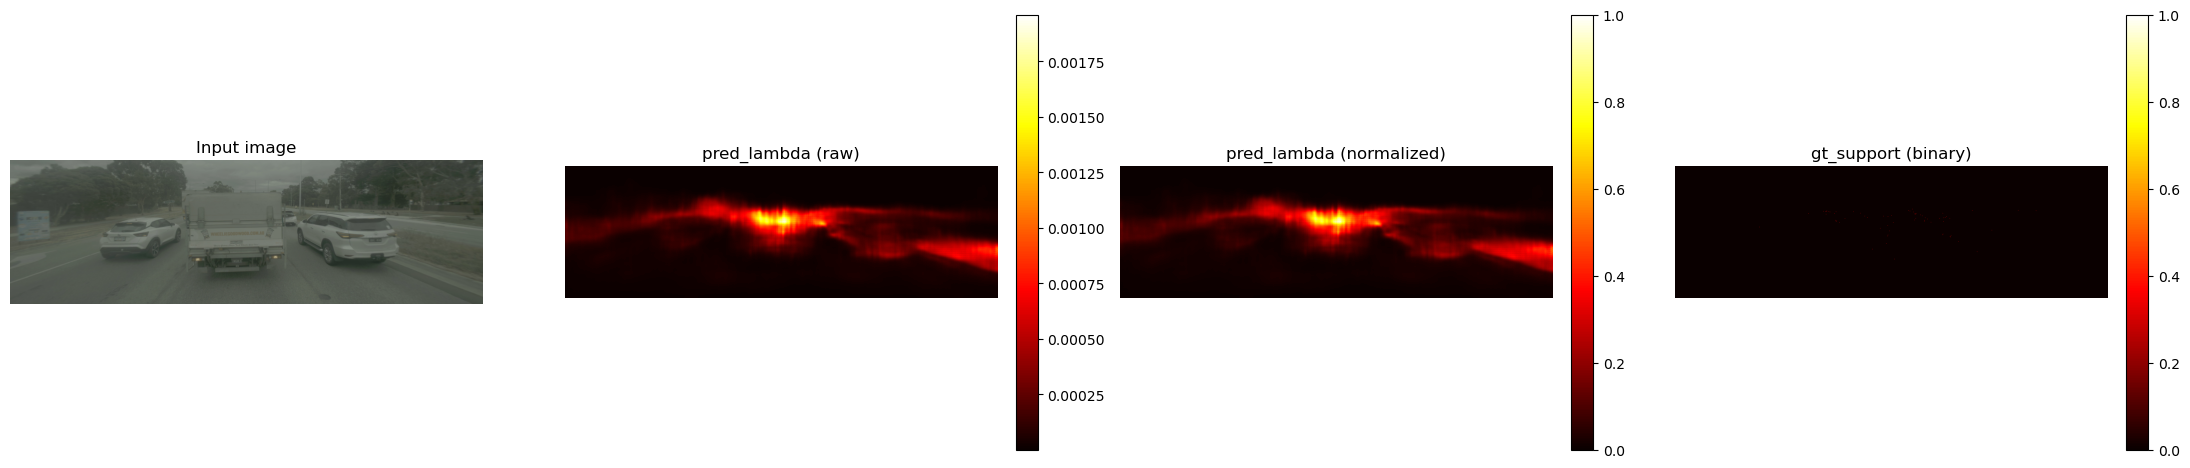

In [5]:
# Load first sample
h5_path_0, key_0 = all_samples[0]
sample = load_h5_sample(h5_path_0, key_0)

img = sample["img"]
pred_lambda = sample["pred_lambda"]
gt_support = sample["gt_support"]
meta = sample["meta"]

res = compute_sample_psnr(pred_lambda, gt_support)

print(f"Sample : {meta['h5_file']} / {meta['sample_key']}")
print(f"Shape  : img={img.shape}, pred_lambda={pred_lambda.shape}, gt_support={gt_support.shape}")
print(f"MSE    : {res['mse']:.8f}")
print(f"PSNR   : {res['psnr']:.4f} dB")

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

axes[0].imshow(img)
axes[0].set_title("Input image")
axes[0].axis("off")

im1 = axes[1].imshow(pred_lambda)
axes[1].set_title("pred_lambda (raw)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(res["pred_norm"], vmin=0.0, vmax=1.0)
axes[2].set_title("pred_lambda (normalized)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

im3 = axes[3].imshow(res["gt_bin"], vmin=0.0, vmax=1.0)
axes[3].set_title("gt_support (binary)")
axes[3].axis("off")
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 6 · Quick sanity check on random samples

In [6]:
assert len(all_samples) > 0, "all_samples is empty."

rng = np.random.default_rng(42)
k = min(10, len(all_samples))
picked_idx = rng.choice(len(all_samples), size=k, replace=False)

psnr_stats = []
for i in picked_idx:
    h5_path, sample_key = all_samples[i]
    s = load_h5_sample(h5_path, sample_key)
    out = compute_sample_psnr(s["pred_lambda"], s["gt_support"])

    psnr_stats.append({
        "h5_file": os.path.basename(h5_path),
        "sample_key": sample_key,
        "mse": out["mse"],
        "psnr_db": out["psnr"],
        "pred_lambda_max": float(np.max(s["pred_lambda"])),
        "gt_count": int((s["gt_support"] > 0).sum()),
    })

for row in psnr_stats:
    print(row)

{'h5_file': 'rank00.h5', 'sample_key': 'sample_000042', 'mse': 0.0030036736274764116, 'psnr_db': 25.22347258580797, 'pred_lambda_max': 0.01483272947371006, 'gt_count': 314}
{'h5_file': 'rank03.h5', 'sample_key': 'sample_000005', 'mse': 0.001232995308447632, 'psnr_db': 29.090385758934666, 'pred_lambda_max': 0.041294705122709274, 'gt_count': 323}
{'h5_file': 'rank00.h5', 'sample_key': 'sample_000043', 'mse': 0.02106281507703999, 'psnr_db': 16.76483585158052, 'pred_lambda_max': 0.001602271688170731, 'gt_count': 338}
{'h5_file': 'rank02.h5', 'sample_key': 'sample_000072', 'mse': 0.007250958220790763, 'psnr_db': 21.396045972216463, 'pred_lambda_max': 0.0047712684608995914, 'gt_count': 193}
{'h5_file': 'rank01.h5', 'sample_key': 'sample_000091', 'mse': 0.00045737232017724024, 'psnr_db': 33.397301221036344, 'pred_lambda_max': 0.07466396689414978, 'gt_count': 215}
{'h5_file': 'rank01.h5', 'sample_key': 'sample_000089', 'mse': 0.0004970025137156843, 'psnr_db': 33.036414147071305, 'pred_lambda_m

## 7 · Interactive Sample Browser

Use the slider to step through samples. Click **"Add to selection"** to mark the current sample. The selected keys are collected in `selected_samples`.

In [7]:
def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) tuples across all rank files,
    sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from an h5 file.

    Returns a dict with:
      img          – (H, W, 3) uint8
      pred_lambda  – (H, W) float32
      gt_support   – (H, W) float32
      ppp          – dict with expected_count, gt_count
      meta         – small metadata dict
    """
    with h5py.File(h5_path, "r") as f:
        g = f[sample_key]

        img = g["img"][()]
        pred_lambda = g["pred_lambda"][()]
        gt_support = g["gt_support"][()]

    pred_lambda = np.asarray(pred_lambda, dtype=np.float64)
    gt_support = np.asarray(gt_support)

    ppp = {
        "expected_count": float(np.sum(pred_lambda)),
        "gt_count": int(np.sum(gt_support > 0)),
    }

    return {
        "img": img,
        "pred_lambda": pred_lambda,
        "gt_support": gt_support,
        "ppp": ppp,
        "meta": {
            "h5_file": os.path.basename(h5_path),
            "sample_key": sample_key,
        }
    }


base_dir = H5_DIRS[ACTIVE_MODEL]
print(f"Active model : {ACTIVE_MODEL}")
print(f"Base dir     : {base_dir}")
print(f"Exists?      : {os.path.isdir(base_dir)}")

if os.path.isdir(base_dir):
    print("Directory content:")
    for name in sorted(os.listdir(base_dir))[:20]:
        print("  ", name)

active_h5_files = sorted(glob.glob(os.path.join(base_dir, "rank*.h5")))
print(f"Found h5 files: {len(active_h5_files)}")
for p in active_h5_files[:10]:
    print("  ", os.path.basename(p))

assert active_h5_files, f"No rank*.h5 files found in: {base_dir}"

all_samples = list_h5_samples(active_h5_files)
assert all_samples, "No samples found inside the h5 files."

print(f"Samples total: {len(all_samples)}")

Active model : test_gen_data_meric_13600264
Base dir     : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test
Exists?      : True
Directory content:
   rank00.h5
   rank01.h5
   rank02.h5
   rank03.h5
Found h5 files: 4
   rank00.h5
   rank01.h5
   rank02.h5
   rank03.h5
Samples total: 500


In [ ]:
GT_DOT_SIZE = 24

import ipywidgets as widgets
from IPython.display import display, clear_output

# ============================================================
# 5 · Visualization helper
# ============================================================

def show_sample_triptych(sample, title_prefix=""):
    img = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support = sample["gt_support"]
    ppp = sample["ppp"]
    meta = sample["meta"]

    ys, xs = np.where(gt_support > 0)

    fig, axes = plt.subplots(1, 3, figsize=(21, 5))

    axes[0].imshow(img, aspect="auto")
    axes[0].set_title(f"{title_prefix}Image\n{meta['sample_key']}")
    axes[0].axis("off")

    im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
    axes[1].set_title(
        rf"{title_prefix}Predicted $\lambda$" + f"\nE[N]={ppp['expected_count']:.2f}"
    )
    axes[1].axis("off")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

    axes[2].imshow(img, aspect="auto")
    axes[2].scatter(xs, ys, s=GT_DOT_SIZE, c="lime", linewidths=0, alpha=0.9)
    axes[2].set_title(f"{title_prefix}GT overlay\nN={ppp['gt_count']}")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()


# ============================================================
# 6 · Interactive sample selection tool
# ============================================================

selected_samples = []   # list of (h5_path, sample_key)

n = len(all_samples)

slider = widgets.IntSlider(
    value=0,
    min=0,
    max=max(0, n - 1),
    step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="700px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆ Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

btn_prev = widgets.Button(
    description="← Prev",
    layout=widgets.Layout(width="100px"),
)

btn_next = widgets.Button(
    description="Next →",
    layout=widgets.Layout(width="100px"),
)

btn_clear = widgets.Button(
    description="Clear selection",
    button_style="warning",
    layout=widgets.Layout(width="150px"),
)

btn_print = widgets.Button(
    description="Print selection",
    layout=widgets.Layout(width="130px"),
)

lbl_status = widgets.Label(value="0 selected")

plot_out = widgets.Output()
select_out = widgets.Output()


def _entry_of_idx(idx):
    h5_path, key = all_samples[idx]
    return (h5_path, key)


def _entry_label(entry):
    h5_path, key = entry
    return f"{os.path.basename(h5_path)} / {key}"


def _update_button_state(idx):
    entry = _entry_of_idx(idx)
    is_selected = entry in selected_samples
    btn_add.value = is_selected
    btn_add.description = "★ In selection" if is_selected else "☆ Add to selection"
    btn_add.button_style = "success" if is_selected else ""


def _refresh_status():
    lbl_status.value = f"{len(selected_samples)} selected"


def _render_selection_list():
    with select_out:
        clear_output(wait=True)
        print("Selected samples:")
        if not selected_samples:
            print("  (none)")
        else:
            for i, entry in enumerate(selected_samples):
                print(f"  {i:3d}: {_entry_label(entry)}")


def _render_current(idx):
    sample = load_h5_sample(*all_samples[idx])
    with plot_out:
        clear_output(wait=True)
        show_sample_triptych(sample, title_prefix=f"[{idx}] ")


def _full_refresh(idx):
    _update_button_state(idx)
    _refresh_status()
    _render_current(idx)
    _render_selection_list()


def _on_slider_change(change):
    if change["name"] == "value":
        _full_refresh(change["new"])


def _on_toggle_change(change):
    if change["name"] != "value":
        return

    idx = slider.value
    entry = _entry_of_idx(idx)

    if change["new"]:
        if entry not in selected_samples:
            selected_samples.append(entry)
    else:
        if entry in selected_samples:
            selected_samples.remove(entry)

    _full_refresh(idx)


def _on_prev_clicked(_):
    slider.value = max(slider.min, slider.value - 1)


def _on_next_clicked(_):
    slider.value = min(slider.max, slider.value + 1)


def _on_clear_clicked(_):
    selected_samples.clear()
    _full_refresh(slider.value)


def _on_print_clicked(_):
    _render_selection_list()


slider.observe(_on_slider_change, names="value")
btn_add.observe(_on_toggle_change, names="value")
btn_prev.on_click(_on_prev_clicked)
btn_next.on_click(_on_next_clicked)
btn_clear.on_click(_on_clear_clicked)
btn_print.on_click(_on_print_clicked)

controls = widgets.HBox([btn_prev, btn_next, btn_add, btn_clear, btn_print])
ui = widgets.VBox([slider, controls, lbl_status, plot_out, select_out])

display(ui)
_full_refresh(0)

In [10]:
print(f"selected_samples = {selected_samples!r}")

selected_samples = [('/mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5', 'sample_000000'), ('/mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5', 'sample_000110'), ('/mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5', 'sample_000066')]


## 8 · Analysis on selected samples

For each selected sample we compute

- the normalized prediction $\hat y$
- the binary GT image $y$
- the MSE
- the PSNR in dB

Because

$$
\mathrm{PSNR} = -10\log_{10}(\mathrm{MSE}),
$$

ranking by PSNR is equivalent to ranking by MSE, but PSNR is often easier to read because it is on a logarithmic dB scale.

Higher PSNR means better agreement.

In [11]:
assert selected_samples, "No samples selected – browse and add at least one above."

selected_results = []

for h5_path, sample_key in selected_samples:
    s = load_h5_sample(h5_path, sample_key)
    out = compute_sample_psnr(s["pred_lambda"], s["gt_support"])

    selected_results.append({
        "h5_file": os.path.basename(h5_path),
        "sample_key": sample_key,
        "mse": out["mse"],
        "psnr_db": out["psnr"],
        "gt_count": s["ppp"]["gt_count"],
        "expected_count": s["ppp"]["expected_count"],
        "pred_lambda_max": float(np.max(s["pred_lambda"])),
    })

selected_results_sorted = sorted(
    selected_results,
    key=lambda x: x["psnr_db"],
    reverse=True
)

for row in selected_results_sorted:
    print(row)

{'h5_file': 'rank00.h5', 'sample_key': 'sample_000110', 'mse': 0.001695946421315961, 'psnr_db': 27.705878721821236, 'gt_count': 229, 'expected_count': 207.0291091493807, 'pred_lambda_max': 0.022377047687768936}
{'h5_file': 'rank01.h5', 'sample_key': 'sample_000066', 'mse': 0.002211316979723672, 'psnr_db': 26.55348999312818, 'gt_count': 295, 'expected_count': 251.10409290188332, 'pred_lambda_max': 0.01357798371464014}
{'h5_file': 'rank00.h5', 'sample_key': 'sample_000000', 'mse': 0.013929374900270502, 'psnr_db': 18.560683726969646, 'gt_count': 67, 'expected_count': 106.85181729313013, 'pred_lambda_max': 0.0019611860625445843}


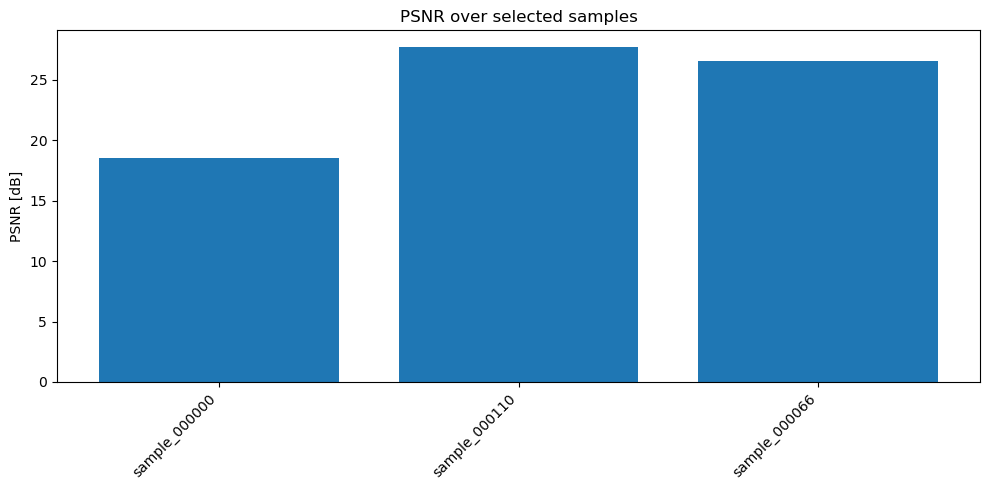

Mean PSNR: 24.2734 dB
Std  PSNR: 4.0668 dB
Min  PSNR: 18.5607 dB
Max  PSNR: 27.7059 dB


In [12]:
assert selected_samples, "No samples selected – browse and add at least one above."

psnr_vals = []
sample_labels = []

for h5_path, sample_key in selected_samples:
    s = load_h5_sample(h5_path, sample_key)
    out = compute_sample_psnr(s["pred_lambda"], s["gt_support"])

    psnr_vals.append(out["psnr"])
    sample_labels.append(sample_key)

plt.figure(figsize=(max(10, len(sample_labels) * 0.8), 5))
plt.bar(range(len(psnr_vals)), psnr_vals)
plt.xticks(range(len(sample_labels)), sample_labels, rotation=45, ha="right")
plt.ylabel("PSNR [dB]")
plt.title("PSNR over selected samples")
plt.tight_layout()
plt.show()

print(f"Mean PSNR: {np.mean(psnr_vals):.4f} dB")
print(f"Std  PSNR: {np.std(psnr_vals):.4f} dB")
print(f"Min  PSNR: {np.min(psnr_vals):.4f} dB")
print(f"Max  PSNR: {np.max(psnr_vals):.4f} dB")

## 9 · Full-dataset PSNR analysis

We now evaluate **all samples** of a model.

For each sample $s$:

1. load `pred_lambda_s` and `gt_support_s`
2. compute the normalized prediction $\hat y_s$
3. compute
   $$
   \mathrm{MSE}_s = \frac{1}{H_sW_s}\sum_{i,j}(y_{s,ij}-\hat y_{s,ij})^2
   $$
4. compute
   $$
   \mathrm{PSNR}_s = 10\log_{10}\left(\frac{1}{\mathrm{MSE}_s}\right)
   $$

Then we summarize the empirical distribution across all samples.

This is a **per-sample image similarity analysis**.
It does **not** directly evaluate PPP count calibration.

In [13]:
def run_psnr_analysis(model_name: str, h5_dir: str, max_samples=None):
    """
    Compute per-sample PSNR statistics over a full model directory.
    """
    h5_files = sorted(glob.glob(os.path.join(h5_dir, "rank*.h5")))
    assert h5_files, f"No rank*.h5 files found in: {h5_dir}"

    entries = list_h5_samples(h5_files)
    assert entries, f"No samples found for model: {model_name}"

    if max_samples is not None:
        entries = entries[:max_samples]

    rows = []
    for h5_path, sample_key in entries:
        s = load_h5_sample(h5_path, sample_key)
        out = compute_sample_psnr(s["pred_lambda"], s["gt_support"])

        rows.append({
            "model": model_name,
            "h5_file": os.path.basename(h5_path),
            "sample_key": sample_key,
            "mse": out["mse"],
            "psnr_db": out["psnr"],
            "gt_count": int((s["gt_support"] > 0).sum()),
            "pred_lambda_max": float(np.max(s["pred_lambda"])),
        })

    return rows

In [14]:
MAX_SAMPLES_PER_MODEL = 10   # set e.g. to 200 for a quick test

all_model_rows = []
for model_name, h5_dir in H5_DIRS.items():
    rows = run_psnr_analysis(model_name, h5_dir, max_samples=MAX_SAMPLES_PER_MODEL)
    all_model_rows.extend(rows)
    print(f"{model_name}: processed {len(rows)} samples")

assert all_model_rows, "No PSNR results computed."

test_gen_data_meric_1500_13606074: processed 10 samples
test_gen_data_meric_13600264: processed 10 samples
test_gen_data_meric_1500_13603608_LR_load_model40000: processed 10 samples


In [20]:
# Summarise results by model
from collections import defaultdict

by_model = defaultdict(list)
for row in all_model_rows:
    by_model[row["model"]].append(row["psnr_db"])

summary = []
for model_name, vals in by_model.items():
    vals = np.asarray(vals, dtype=np.float64)
    summary.append({
        "model": model_name,
        "n": len(vals),
        "mean_psnr": float(np.mean(vals)),
        "std_psnr": float(np.std(vals)),
        "median_psnr": float(np.median(vals)),
        "min_psnr": float(np.min(vals)),
        "max_psnr": float(np.max(vals)),
    })

summary = sorted(summary, key=lambda x: x["mean_psnr"], reverse=True)

for row in summary:
    print(row)

{'model': 'test_gen_data_meric_13600264', 'n': 10, 'mean_psnr': 24.1992070033668, 'std_psnr': 9.088598479525187, 'median_psnr': 29.114828157320556, 'min_psnr': 10.218220938004094, 'max_psnr': 33.74150680862857}
{'model': 'test_gen_data_meric_1500_13603608_LR_load_model40000', 'n': 10, 'mean_psnr': 23.981597430317485, 'std_psnr': 5.239890621427111, 'median_psnr': 26.284683557819776, 'min_psnr': 13.511122089676569, 'max_psnr': 29.184308502662525}
{'model': 'test_gen_data_meric_1500_13606074', 'n': 10, 'mean_psnr': 9.873446532742959, 'std_psnr': 3.263441066777856, 'median_psnr': 8.69437026615239, 'min_psnr': 6.497093732211347, 'max_psnr': 16.00481122913308}


/tmp/ipykernel_85835/3709462003.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=model_names, showmeans=True)


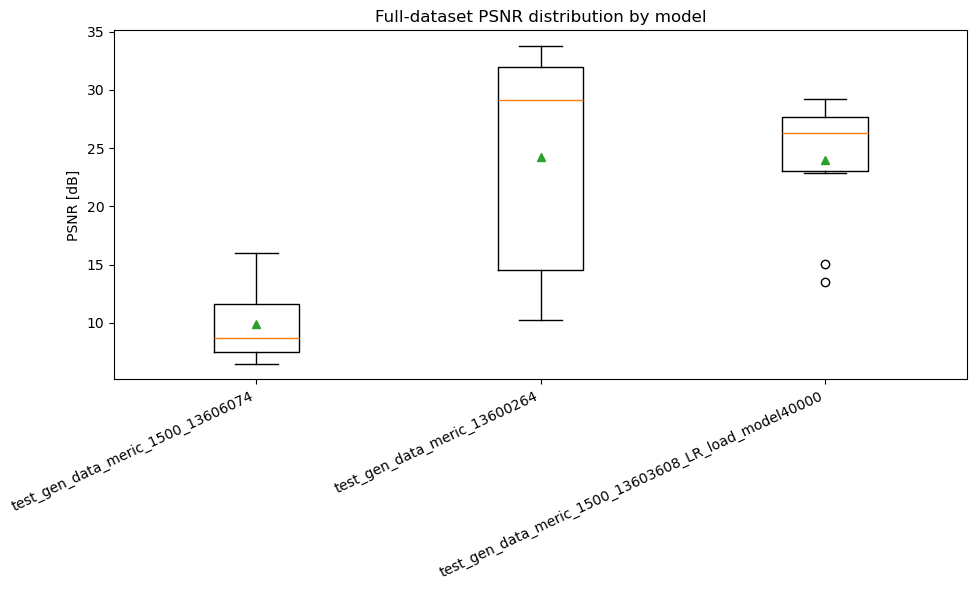

In [21]:
# Boxplot across models
model_names = list(by_model.keys())
data = [by_model[m] for m in model_names]

plt.figure(figsize=(max(10, 2 + 2 * len(model_names)), 6))
plt.boxplot(data, labels=model_names, showmeans=True)
plt.ylabel("PSNR [dB]")
plt.title("Full-dataset PSNR distribution by model")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 10 · Interpretation

### How to read the score

Because

$$
\mathrm{PSNR} = -10\log_{10}(\mathrm{MSE}),
$$

the score increases logarithmically as the reconstruction error decreases.

A model with higher mean PSNR tends to place its mass more consistently on the GT support regions.

### What this score captures well

PSNR is useful when you want to measure:

- overall spatial agreement
- sharpness versus spreading of the predicted heatmap
- relative reconstruction quality after normalization

### What this score does **not** capture well

PSNR does **not** explicitly respect the PPP semantics:

- it does not evaluate count calibration
- it ignores the probabilistic interpretation of intensity mass
- it depends on the normalization of `pred_lambda`

So PSNR should be interpreted as an **image similarity score**, not as a full probabilistic PPP metric.

In [22]:
# Optional: inspect the best and worst sample per model

for model_name in by_model.keys():
    rows = [r for r in all_model_rows if r["model"] == model_name]
    rows_sorted = sorted(rows, key=lambda x: x["psnr_db"])

    worst = rows_sorted[0]
    best = rows_sorted[-1]

    print("=" * 80)
    print(f"MODEL: {model_name}")
    print("Worst :", worst)
    print("Best  :", best)

MODEL: test_gen_data_meric_1500_13606074
Worst : {'model': 'test_gen_data_meric_1500_13606074', 'h5_file': 'rank00.h5', 'sample_key': 'sample_000003', 'mse': 0.22402197762168194, 'psnr_db': 6.497093732211347, 'gt_count': 162, 'pred_lambda_max': 0.0008347656694240868}
Best  : {'model': 'test_gen_data_meric_1500_13606074', 'h5_file': 'rank00.h5', 'sample_key': 'sample_000000', 'mse': 0.025091052381104238, 'psnr_db': 16.00481122913308, 'gt_count': 264, 'pred_lambda_max': 0.0006030054064467549}
MODEL: test_gen_data_meric_13600264
Worst : {'model': 'test_gen_data_meric_13600264', 'h5_file': 'rank00.h5', 'sample_key': 'sample_000007', 'mse': 0.09509942831320432, 'psnr_db': 10.218220938004094, 'gt_count': 329, 'pred_lambda_max': 0.0006836015963926911}
Best  : {'model': 'test_gen_data_meric_13600264', 'h5_file': 'rank00.h5', 'sample_key': 'sample_000006', 'mse': 0.000422521992498651, 'psnr_db': 33.74150680862857, 'gt_count': 158, 'pred_lambda_max': 0.05167803540825844}
MODEL: test_gen_data_mer